In [1]:
import numpy as np
import matplotlib.pyplot as plt
import glob
from tqdm import tqdm

# import sys
# sys.path.append("..")
from msna.our_method.msna_pipeline import MSNA_pipeline
from msna.msna_common import get_files, read_msna, metrics
# sys.path.append("../other_methods")
from msna.other_methods.find_peaks import PeakFinderPipeline
from msna.other_methods.wavelet import WaveletPipeline
from msna.other_methods.spike_deconvolution import SpikeDeconvolverPipeline
from msna.other_methods.dtct import DTCT_pipeline
from msna.other_methods.dtcts import DTCT2

/Users/trippdow/Projects/HealthIntelligence/msna/msna/our_method/msna_pipeline.py:49: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.cnn.load_state_dict(torch.load(f"{ou

In [2]:
 
files = get_files("../../../Archival/MSNAS/MSNA*/MSNA*burstcomments*.txt")[-4:]
our_pipeline = MSNA_pipeline(sampling_rate=250)
wavelet_pipeline = WaveletPipeline(scale=10, sr=250)
peak_finder_pipeline = PeakFinderPipeline()
spike_deconvolver_pipeline = SpikeDeconvolverPipeline(n=128)
dtct_pipeline = DTCT_pipeline(DTCT2, sampling_rate=1000, low=500, high=500)
our_pipeline.load("../our_method/pretrained")
wavelet_pipeline.load("../other_methods/pretrained/wavelet_pretrained")
dtct_pipeline.load("../other_methods/pretrained/dtct_pretrained")

/Users/trippdow/Projects/HealthIntelligence/msna/msna/other_methods/dtct.py:42: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.dtct.load_state_dict(torch.load(f"{output_

  0%|                                                     | 0/1 [00:00<?, ?it/s]

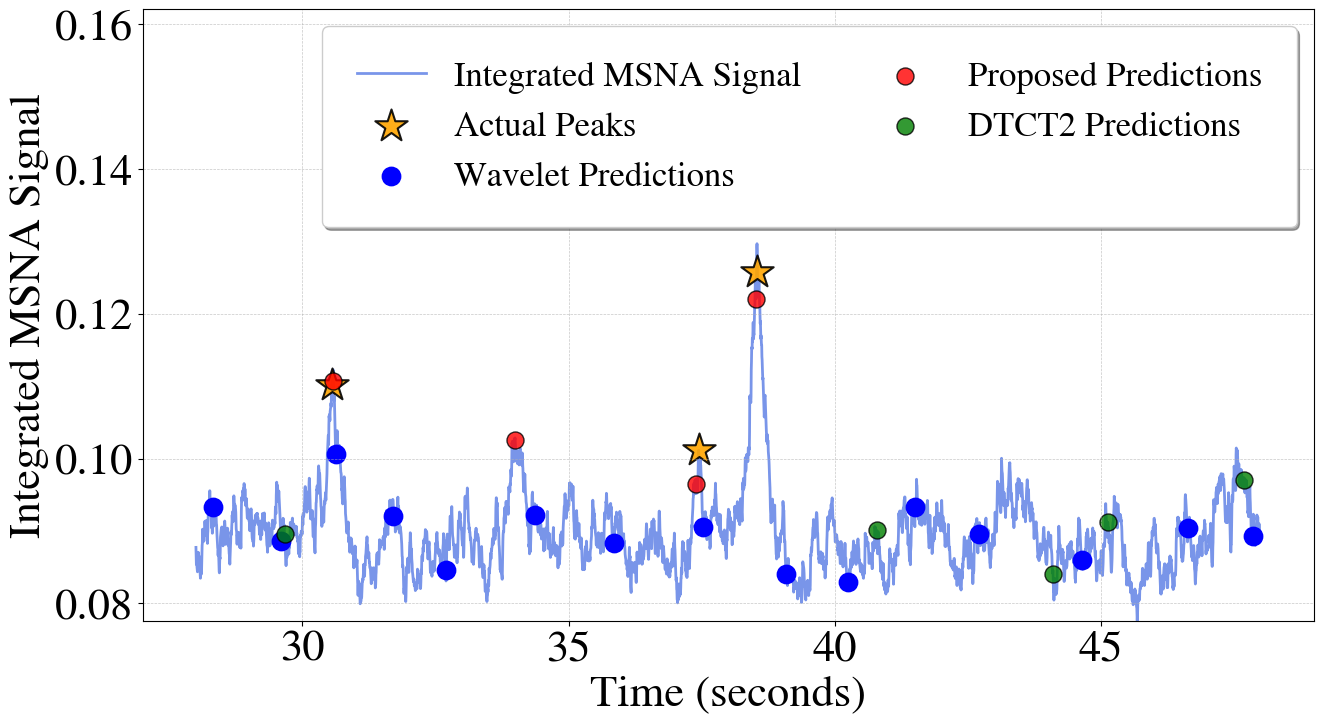

100%|█████████████████████████████████████████████| 1/1 [00:08<00:00,  8.23s/it]


In [17]:
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rc('font', family='STIXGeneral', size=32) 

def get_valid_indices(indices, start, end):
    return (indices < end) & (indices > start)

for filename in tqdm(files[2:3]):
    df = read_msna(filename)

    if df is not None:
        
        # Extract indices of the actual BURST events
        actual_burst_indices = df[df['BURST'] != 0].index.to_numpy()
        
        our_method_burst_indices = our_pipeline.predict(filename)
        wavelet_burst_indices = wavelet_pipeline.predict(filename)
        dtct_burst_indices = dtct_pipeline.predict(filename)
        # spike_deconvolver_burst_indices = spike_deconvolver_pipeline.predict(filename)
        # peak_finder_burst_indices = peak_finder_pipeline.predict(filename)

        plot_start = 7000
        plot_end = plot_start + 5000

        # Filter indices to be within plotting range
        actual_burst_indices = actual_burst_indices[get_valid_indices(actual_burst_indices, plot_start, plot_end)]
        our_method_burst_indices = our_method_burst_indices[get_valid_indices(our_method_burst_indices, plot_start, plot_end)]
        wavelet_burst_indices = wavelet_burst_indices[get_valid_indices(wavelet_burst_indices, plot_start, plot_end)] + 1 
        dtct_burst_indices = dtct_burst_indices[get_valid_indices(dtct_burst_indices, plot_start, plot_end)] 
        # spike_deconvolver_burst_indices = spike_deconvolver_burst_indices[get_valid_indices(spike_deconvolver_burst_indices, plot_start, plot_end)]
        # peak_finder_burst_indices = peak_finder_burst_indices[get_valid_indices(peak_finder_burst_indices, plot_start, plot_end)]

        signal = df['Integrated MSNA'][plot_start:plot_end]
        x_values = np.arange(plot_start, plot_end) / 250.0

        sz = 600

        # Plot the signal with improved visibility
        plt.figure(figsize=(14, 8))
        plt.plot(x_values, signal, label="Integrated MSNA Signal", linewidth=2, color="royalblue", alpha=0.7, zorder=1)

        # Scatter plots for burst markers
        plt.scatter(x_values[actual_burst_indices-plot_start], df['Integrated MSNA'][actual_burst_indices], 
                    marker="*", color="orange", edgecolors="black", s=sz, label="Actual Peaks", alpha=0.9, linewidths=1.5)
        plt.scatter(x_values[wavelet_burst_indices-plot_start], df['Integrated MSNA'][wavelet_burst_indices], 
                    marker=".", color="blue", s=sz, label="Wavelet Predictions", linewidths=2)
        plt.scatter(x_values[our_method_burst_indices-plot_start], df['Integrated MSNA'][our_method_burst_indices], 
                    marker=".", color="red", edgecolors="black", s=sz, label="Proposed Predictions", alpha=0.8)
        plt.scatter(x_values[dtct_burst_indices-plot_start], df['Integrated MSNA'][dtct_burst_indices], 
                    marker=".", color="green", edgecolors="black", s=sz, label="DTCT2 Predictions", alpha=0.8)
        # plt.scatter(x_values[peak_finder_burst_indices-plot_start], df['Integrated MSNA'][peak_finder_burst_indices], 
        #             marker="x", color="blue", edgecolors="black", s=sz, label="Find Peaks", alpha=0.8)

        y_min, y_max = df['Integrated MSNA'][plot_start:plot_end].min(), df['Integrated MSNA'][plot_start:plot_end].max()

        plt.ylim(y_min, y_max * 1.25)


        # Formatting for an academic-style plot
        # plt.title("Detected Peaks vs Actual Peaks", fontsize=20, fontweight='bold')
        plt.xlabel("Time (seconds)", fontsize=32)
        plt.ylabel("Integrated MSNA Signal", fontsize=32)
        plt.legend(fontsize=25, loc="upper right", frameon=True, fancybox=True, shadow=True, borderpad=1, ncol=2)
        plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.7)

        # Improve layout
        plt.tight_layout()
        plt.savefig("example.png", format='png', dpi=600)
        plt.show()
